# Eksplorasi awal Pada Data, Baseline Model Awal, dan Analisis Stasioner pada PDB Industri Makanan dan Minuman Indonesia (2010 Q1 – 2026 Q3)

*Daffa Muhammad Khrisadi / 24083010062 / Analisis Deret Waktu A*

---
## 1. Pemuatan Data & Pemeriksaan Kualitas Data

In [8]:
import pathlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)

DATA_PATH = pathlib.Path('../data/pdb_industri_makanan_minuman_bps.csv')
df = pd.read_csv(DATA_PATH)
df['tanggal'] = pd.to_datetime(df['tanggal'])

print(f'Dimensi dataset: {df.shape[0]} baris x {df.shape[1]} kolom')
print('\nTipe data per kolom:')
print(df.dtypes)
display(df.head(5))
display(df.tail(5))

Dimensi dataset: 67 baris x 8 kolom

Tipe data per kolom:
periode                                            str
tanggal                                 datetime64[us]
tahun                                            int64
triwulan                                         int64
pdb_mamin_adhk_miliar_rp                       float64
pdb_mamin_adhb_miliar_rp                       float64
pdb_industri_nonmigas_adhk_miliar_rp           float64
hari_ramadan_idul_fitri                          int64
dtype: object


,periode,tanggal,tahun,triwulan,pdb_mamin_adhk_miliar_rp,pdb_mamin_adhb_miliar_rp,pdb_industri_nonmigas_adhk_miliar_rp,hari_ramadan_idul_fitri
0,2010-Q1,2010-01-01,2010,1,85184.0,84636.9,311629.3,0
1,2010-Q2,2010-04-01,2010,2,88613.6,87305.4,318492.0,0
2,2010-Q3,2010-07-01,2010,3,93661.2,93999.2,324139.8,32
3,2010-Q4,2010-10-01,2010,4,92984.3,94501.6,324677.5,0
4,2011-Q1,2011-01-01,2011,1,94319.5,96680.8,330619.3,0


,periode,tanggal,tahun,triwulan,pdb_mamin_adhk_miliar_rp,pdb_mamin_adhb_miliar_rp,pdb_industri_nonmigas_adhk_miliar_rp,hari_ramadan_idul_fitri
62,2025-Q3,2025-07-01,2025,3,243920.9,432640.9,644173.6,0
63,2025-Q4,2025-10-01,2025,4,246747.0,445562.6,644431.5,0
64,2026-Q1,2026-01-01,2026,1,247756.4,452420.8,643916.7,32
65,2026-Q2,2026-04-01,2026,2,249967.8,460184.5,651614.3,0
66,2026-Q3,2026-07-01,2026,3,261225.3,487258.1,682073.0,0


## Analisis Integritas Data & Gambaran Deskriptif

In [9]:
missing_df = pd.DataFrame({
    'jumlah_null': df.isna().sum(),
    'persentase_null (%)': (df.isna().mean() * 100).round(2),
})
expected_periods = (
    pd.period_range(start='2010Q1', end='2026Q3', freq='Q')
    .astype(str)
    .str.replace('Q', '-Q', regex=False)
)
missing_quarters = sorted(set(expected_periods) - set(df['periode']))
dup_count = int(df['periode'].duplicated().sum())

print('=== Audit Nilai Hilang & Kontinuitas Waktu ===')
display(missing_df)
print(f'Triwulan terlewat (2010-Q1 s.d. 2026-Q3) : {len(missing_quarters)}')
print(f'Duplikasi periode triwulan               : {dup_count}')

df['pangsa_nonmigas_persen'] = (
    df['pdb_mamin_adhk_miliar_rp'] / df['pdb_industri_nonmigas_adhk_miliar_rp'] * 100
)
summary_cols = [
    'pdb_mamin_adhk_miliar_rp',
    'pdb_mamin_adhb_miliar_rp',
    'pangsa_nonmigas_persen',
    'hari_ramadan_idul_fitri',
]
display(df[summary_cols].describe().round(2))

=== Audit Nilai Hilang & Kontinuitas Waktu ===


,jumlah_null,persentase_null (%)
periode,0,0.0
tanggal,0,0.0
tahun,0,0.0
triwulan,0,0.0
pdb_mamin_adhk_miliar_rp,0,0.0
pdb_mamin_adhb_miliar_rp,0,0.0
pdb_industri_nonmigas_adhk_miliar_rp,0,0.0
hari_ramadan_idul_fitri,0,0.0


Triwulan terlewat (2010-Q1 s.d. 2026-Q3) : 0
Duplikasi periode triwulan               : 0


,pdb_mamin_adhk_miliar_rp,pdb_mamin_adhb_miliar_rp,pangsa_nonmigas_persen,hari_ramadan_idul_fitri
count,67.00,67.00,67.00,67.00
mean,166771.15,236709.51,34.04,8.12
std,48653.10,110887.49,3.58,12.95
min,85184.00,84636.90,27.34,0.00
25%,123047.40,135712.45,30.57,0.00
50%,171813.30,231521.00,35.05,0.00
75%,204285.30,309645.50,37.29,16.00
max,261225.30,487258.10,39.08,32.00


---
## 2. Eksplorasi Data (EDA): Pembagian Kronologis, Dekomposisi Musiman, & Pola Kalender

# Visualisasi Tren Historis & Pembagian Himpunan Data

Training Set   : 2010-Q1 s.d. 2022-Q3 (51 observasi)
Validation Set : 2022-Q4 s.d. 2024-Q3 (8 observasi)
Test Set       : 2024-Q4 s.d. 2026-Q3 (8 observasi)


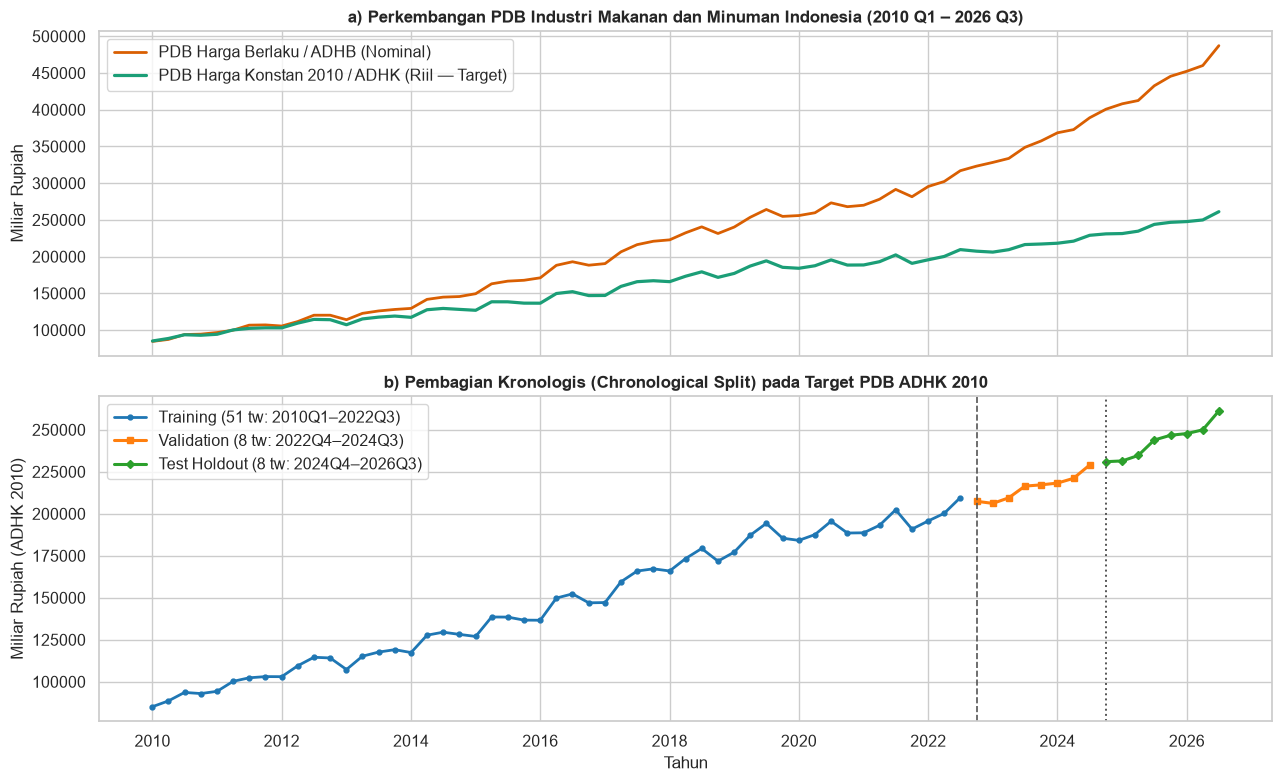

In [10]:
# Pembagian Kronologis (Chronological Split): Train (51) | Validation (8) | Test (8)
N_VAL = 8
N_TEST = 8
N_TRAIN = len(df) - N_VAL - N_TEST

train_df = df.iloc[:N_TRAIN].copy()
val_df = df.iloc[N_TRAIN:N_TRAIN + N_VAL].copy()
test_df = df.iloc[N_TRAIN + N_VAL:].copy()

print(f"Training Set   : {train_df['periode'].iloc[0]} s.d. {train_df['periode'].iloc[-1]} ({len(train_df)} observasi)")
print(f"Validation Set : {val_df['periode'].iloc[0]} s.d. {val_df['periode'].iloc[-1]} ({len(val_df)} observasi)")
print(f"Test Set       : {test_df['periode'].iloc[0]} s.d. {test_df['periode'].iloc[-1]} ({len(test_df)} observasi)")

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Panel (a): Perbandingan Harga Berlaku (Nominal) vs Harga Konstan 2010 (Riil)
axes[0].plot(df['tanggal'], df['pdb_mamin_adhb_miliar_rp'], color='#d95f02', lw=2.0, label='PDB Harga Berlaku / ADHB (Nominal)')
axes[0].plot(df['tanggal'], df['pdb_mamin_adhk_miliar_rp'], color='#1b9e77', lw=2.3, label='PDB Harga Konstan 2010 / ADHK (Riil — Target)')
axes[0].set_title('a) Perkembangan PDB Industri Makanan dan Minuman Indonesia (2010 Q1 – 2026 Q3)', fontweight='bold')
axes[0].set_ylabel('Miliar Rupiah')
axes[0].legend(loc='upper left')

# Panel (b): Pembagian Kronologis Train, Validation, dan Test pada Target ADHK
axes[1].plot(train_df['tanggal'], train_df['pdb_mamin_adhk_miliar_rp'], color='#1f77b4', marker='o', ms=3.5, lw=2.0, label=f'Training ({len(train_df)} tw: 2010Q1–2022Q3)')
axes[1].plot(val_df['tanggal'], val_df['pdb_mamin_adhk_miliar_rp'], color='#ff7f0e', marker='s', ms=4.5, lw=2.2, label=f'Validation ({len(val_df)} tw: 2022Q4–2024Q3)')
axes[1].plot(test_df['tanggal'], test_df['pdb_mamin_adhk_miliar_rp'], color='#2ca02c', marker='D', ms=4.5, lw=2.2, label=f'Test Holdout ({len(test_df)} tw: 2024Q4–2026Q3)')
axes[1].axvline(val_df['tanggal'].iloc[0], color='#555555', ls='--', lw=1.2)
axes[1].axvline(test_df['tanggal'].iloc[0], color='#555555', ls=':', lw=1.4)
axes[1].set_title('b) Pembagian Kronologis (Chronological Split) pada Target PDB ADHK 2010', fontweight='bold')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Miliar Rupiah (ADHK 2010)')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

# Visualisasi Dekomposisi Musiman, Efek Kalender, & Outlier

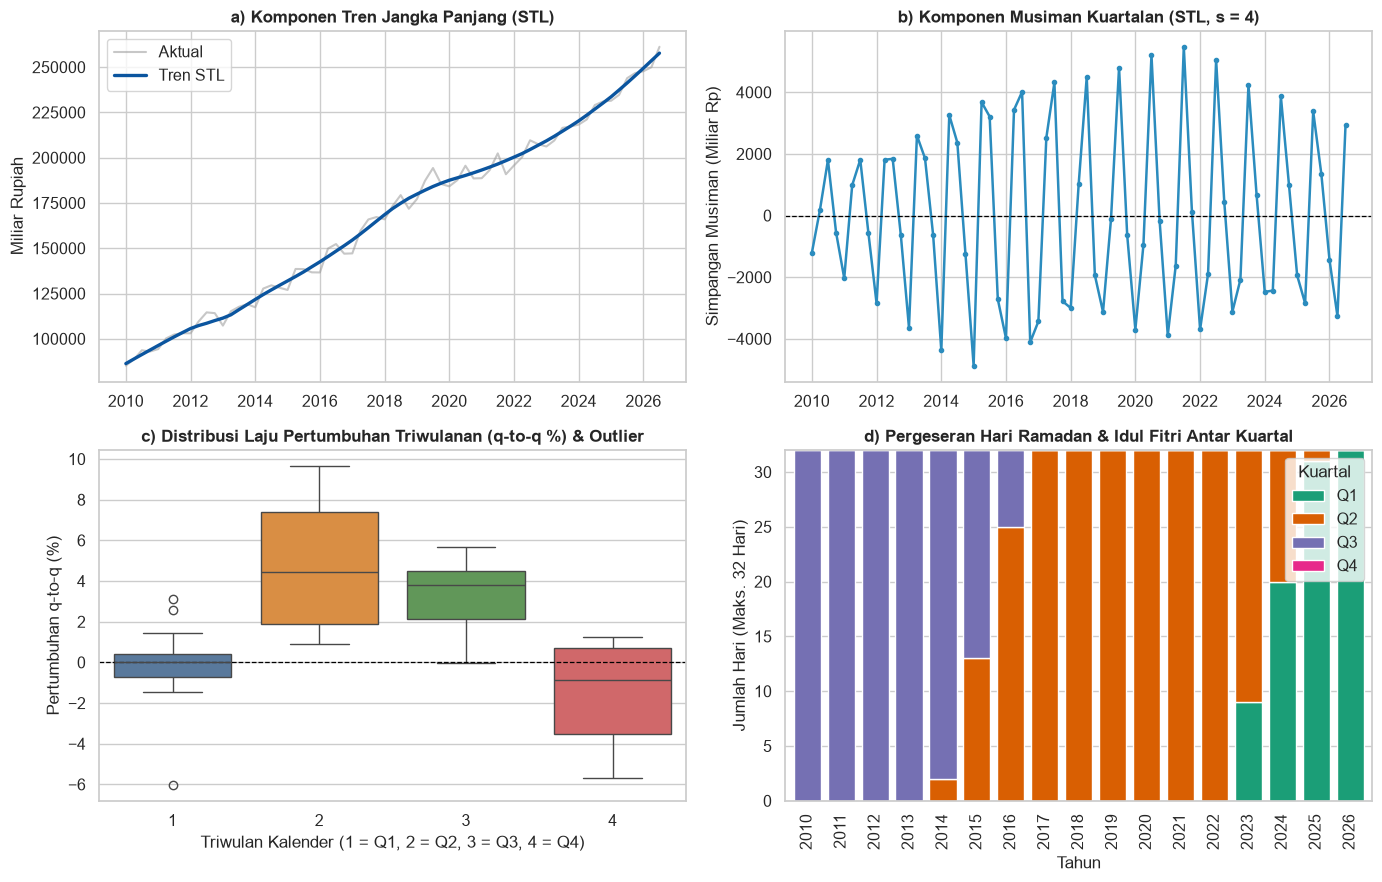

Observasi dengan guncangan struktural menonjol (|Robust Z| > 2.8):


,periode,pdb_mamin_adhk_miliar_rp,pertumbuhan_qoq_persen,hari_ramadan_idul_fitri,robust_z_resid_stl
10,2012-Q3,114593.7,4.613757,32,7.33
11,2012-Q4,114171.8,-0.368170,0,8.34
22,2015-Q3,138510.1,-0.038971,19,-2.91
24,2016-Q1,136633.8,-0.050694,0,-3.35
28,2017-Q1,147160.7,0.109524,0,-6.94
31,2017-Q4,167236.1,0.800079,0,8.87
35,2018-Q4,171813.3,-4.197583,0,-6.81
37,2019-Q2,187207.1,5.648600,32,9.30
38,2019-Q3,194289.2,3.783030,0,9.48
43,2020-Q4,188550.4,-3.586690,0,-5.19


In [11]:
stl_fit = STL(df['pdb_mamin_adhk_miliar_rp'].values, period=4, robust=True).fit()
df['pertumbuhan_qoq_persen'] = df['pdb_mamin_adhk_miliar_rp'].pct_change() * 100

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) Komponen Tren Jangka Panjang STL
axes[0, 0].plot(df['tanggal'], df['pdb_mamin_adhk_miliar_rp'], color='#999999', alpha=0.55, label='Aktual')
axes[0, 0].plot(df['tanggal'], stl_fit.trend, color='#0b559f', lw=2.4, label='Tren STL')
axes[0, 0].set_title('a) Komponen Tren Jangka Panjang (STL)', fontweight='bold')
axes[0, 0].set_ylabel('Miliar Rupiah')
axes[0, 0].legend()

# (b) Komponen Musiman Kuartalan STL
axes[0, 1].plot(df['tanggal'], stl_fit.seasonal, color='#2b8cbe', lw=1.8, marker='o', ms=3)
axes[0, 1].axhline(0, color='black', ls='--', lw=0.9)
axes[0, 1].set_title('b) Komponen Musiman Kuartalan (STL, s = 4)', fontweight='bold')
axes[0, 1].set_ylabel('Simpangan Musiman (Miliar Rp)')

# (c) Distribusi Pertumbuhan q-to-q per Triwulan
sns.boxplot(
    data=df.dropna(subset=['pertumbuhan_qoq_persen']),
    x='triwulan',
    y='pertumbuhan_qoq_persen',
    palette=['#4e79a7', '#f28e2b', '#59a14f', '#e15759'],
    ax=axes[1, 0],
)
axes[1, 0].axhline(0, color='black', ls='--', lw=0.9)
axes[1, 0].set_title('c) Distribusi Laju Pertumbuhan Triwulanan (q-to-q %) & Outlier', fontweight='bold')
axes[1, 0].set_xlabel('Triwulan Kalender (1 = Q1, 2 = Q2, 3 = Q3, 4 = Q4)')
axes[1, 0].set_ylabel('Pertumbuhan q-to-q (%)')

# (d) Pergeseran Hari Ramadan & Idul Fitri Antar Kuartal
pivot_ram = df.pivot(index='tahun', columns='triwulan', values='hari_ramadan_idul_fitri').fillna(0)
pivot_ram.columns = ['Q1', 'Q2', 'Q3', 'Q4']
pivot_ram.plot(
    kind='bar',
    stacked=True,
    ax=axes[1, 1],
    color=['#1b9e77', '#d95f02', '#7570b3', '#e7298a'],
    width=0.8,
)
axes[1, 1].set_title('d) Pergeseran Hari Ramadan & Idul Fitri Antar Kuartal', fontweight='bold')
axes[1, 1].set_xlabel('Tahun')
axes[1, 1].set_ylabel('Jumlah Hari (Maks. 32 Hari)')
axes[1, 1].legend(title='Kuartal', loc='upper right')

plt.tight_layout()
plt.show()

# Deteksi simpangan ireguler menonjol menggunakan Robust Z-Score berbasis MAD
stl_resid = stl_fit.resid
mad = np.median(np.abs(stl_resid - np.median(stl_resid)))
robust_z = 0.6745 * (stl_resid - np.median(stl_resid)) / mad
outlier_rows = df.loc[
    np.abs(robust_z) > 2.8,
    ['periode', 'pdb_mamin_adhk_miliar_rp', 'pertumbuhan_qoq_persen', 'hari_ramadan_idul_fitri'],
].copy()
outlier_rows['robust_z_resid_stl'] = robust_z[np.abs(robust_z) > 2.8].round(2)
print('Observasi dengan guncangan struktural menonjol (|Robust Z| > 2.8):')
display(outlier_rows)

---
## 3. Visualisasi & Pembuktian Ketidakstasioneran Data

# Visualisasi Stasioneritas Rata-Rata dan Varians

Estimasi Optimal Lambda Box-Cox (Training Set) : 0.6817
Interval Kepercayaan 95% Lambda                : [-0.538, 1.950]


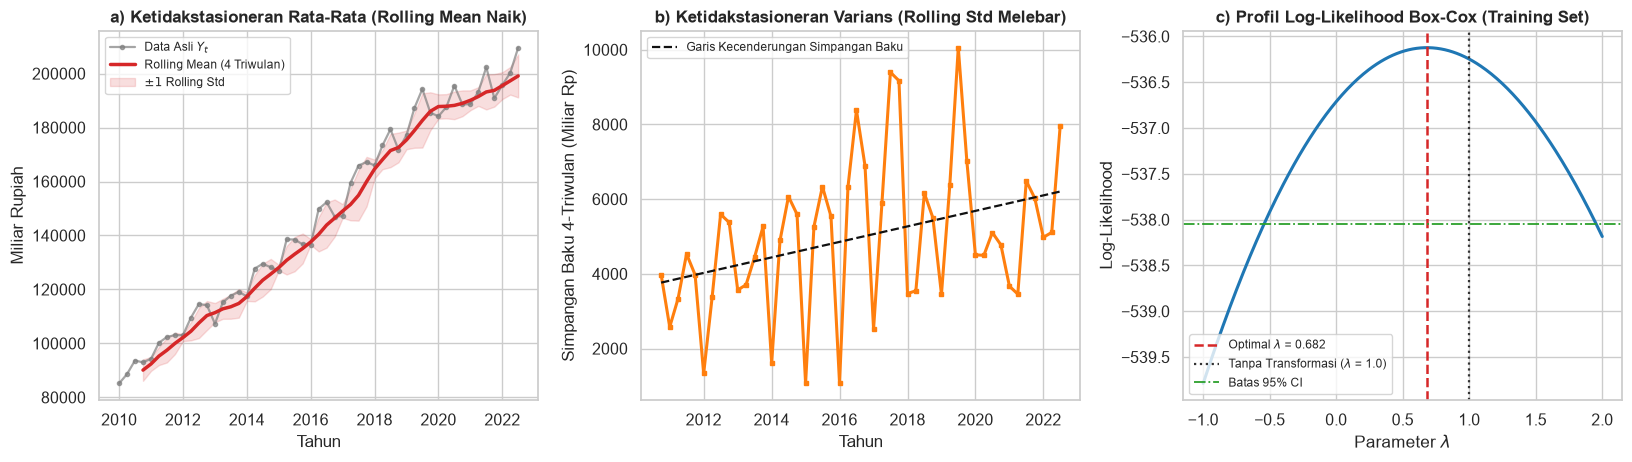

In [12]:
# Seluruh evaluasi stasioneritas dilakukan murni pada Training Set (N = 51) untuk mencegah kebocoran data
y_train = train_df['pdb_mamin_adhk_miliar_rp'].values
dates_train = train_df['tanggal']

roll_mean_4 = pd.Series(y_train).rolling(window=4).mean()
roll_std_4 = pd.Series(y_train).rolling(window=4).std()

# Estimasi parameter Box-Cox pada Training Set
_, lambda_bc = stats.boxcox(y_train)
lmbda_grid = np.linspace(-1.0, 2.0, 300)
llf_vals = np.array([stats.boxcox_llf(lmb, y_train) for lmb in lmbda_grid])
max_llf = stats.boxcox_llf(lambda_bc, y_train)
ci_limit = max_llf - 0.5 * stats.chi2.ppf(0.95, df=1)
ci_bounds = lmbda_grid[llf_vals >= ci_limit]

print(f'Estimasi Optimal Lambda Box-Cox (Training Set) : {lambda_bc:.4f}')
print(f'Interval Kepercayaan 95% Lambda                : [{ci_bounds.min():.3f}, {ci_bounds.max():.3f}]')

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# (a) Ketidakstasioneran terhadap Rata-Rata (Rolling Mean)
axes[0].plot(dates_train, y_train, color='#7f7f7f', alpha=0.7, lw=1.6, marker='o', ms=3, label='Data Asli $Y_t$')
axes[0].plot(dates_train, roll_mean_4, color='#d62728', lw=2.5, label='Rolling Mean (4 Triwulan)')
axes[0].fill_between(
    dates_train,
    roll_mean_4 - roll_std_4,
    roll_mean_4 + roll_std_4,
    color='#d62728',
    alpha=0.15,
    label='$\\pm 1$ Rolling Std',
)
axes[0].set_title('a) Ketidakstasioneran Rata-Rata (Rolling Mean Naik)', fontweight='bold')
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('Miliar Rupiah')
axes[0].legend(loc='upper left', fontsize=8.8)

# (b) Ketidakstasioneran terhadap Varians (Rolling Std)
axes[1].plot(dates_train, roll_std_4, color='#ff7f0e', lw=2.2, marker='s', ms=3.5)
z_trend = np.polyfit(np.arange(3, len(y_train)), roll_std_4.iloc[3:].values, 1)
axes[1].plot(
    dates_train.iloc[3:],
    np.polyval(z_trend, np.arange(3, len(y_train))),
    color='#111111',
    ls='--',
    lw=1.6,
    label='Garis Kecenderungan Simpangan Baku',
)
axes[1].set_title('b) Ketidakstasioneran Varians (Rolling Std Melebar)', fontweight='bold')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Simpangan Baku 4-Triwulan (Miliar Rp)')
axes[1].legend(loc='upper left', fontsize=8.8)

# (c) Profil Log-Likelihood Box-Cox
axes[2].plot(lmbda_grid, llf_vals, color='#1f77b4', lw=2.2)
axes[2].axvline(lambda_bc, color='#d62728', ls='--', lw=1.8, label=f'Optimal $\\lambda$ = {lambda_bc:.3f}')
axes[2].axvline(1.0, color='#333333', ls=':', lw=1.6, label='Tanpa Transformasi ($\\lambda$ = 1.0)')
axes[2].axhline(ci_limit, color='#2ca02c', ls='-.', lw=1.3, label='Batas 95% CI')
axes[2].set_title('c) Profil Log-Likelihood Box-Cox (Training Set)', fontweight='bold')
axes[2].set_xlabel('Parameter $\\lambda$')
axes[2].set_ylabel('Log-Likelihood')
axes[2].legend(loc='lower left', fontsize=8.8)

plt.tight_layout()
plt.show()

# Autokorelasi & Uji ADF dan KPSS

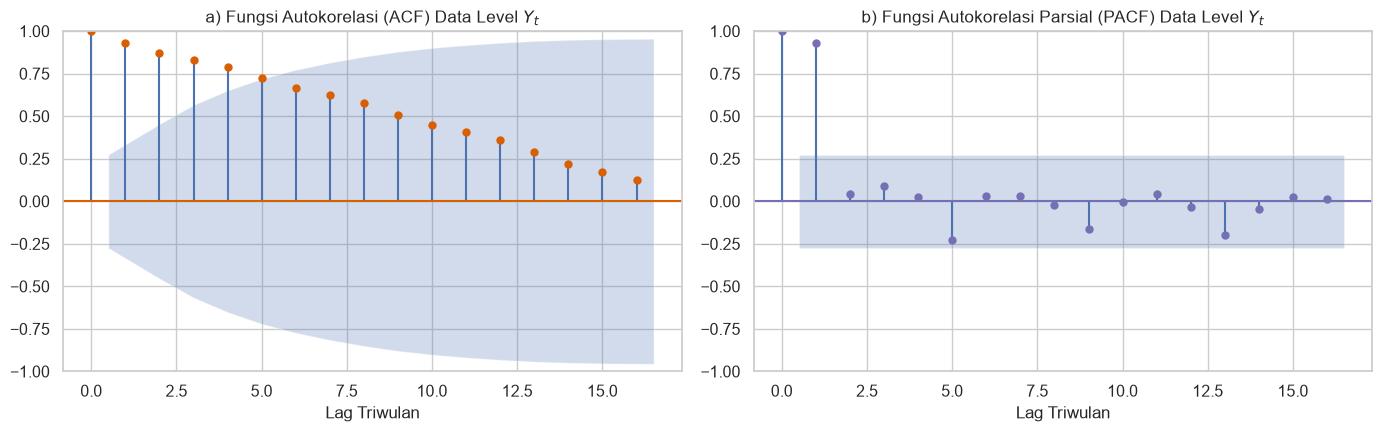

,Deret Uji (Training Set),ADF Stat (c),ADF p-value (c),ADF p-value (ct),KPSS Stat (c),KPSS p-value (c),Kesimpulan (alpha = 5%)
0,Level Asli Y_t (Miliar Rupiah),-0.4254,0.9058,0.0571,1.1251,0.01,TIDAK STASIONER
1,Level Tertransformasi ln(Y_t),-1.8490,0.3564,0.9946,1.1192,0.01,TIDAK STASIONER


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_acf(y_train, lags=16, ax=axes[0], color='#d95f02', title='a) Fungsi Autokorelasi (ACF) Data Level $Y_t$')
plot_pacf(y_train, lags=16, ax=axes[1], color='#7570b3', method='ywm', title='b) Fungsi Autokorelasi Parsial (PACF) Data Level $Y_t$')
axes[0].set_xlabel('Lag Triwulan')
axes[1].set_xlabel('Lag Triwulan')
plt.tight_layout()
plt.show()

def check_level_stationarity(arr: np.ndarray, name: str) -> dict:
    adf_stat_c, adf_p_c, _, _, _, _ = adfuller(arr, regression='c', autolag='AIC')
    adf_stat_ct, adf_p_ct, _, _, _, _ = adfuller(arr, regression='ct', autolag='AIC')
    kpss_stat_c, kpss_p_c, _, _ = kpss(arr, regression='c', nlags='auto')
    is_stationary = (adf_p_c < 0.05) and (kpss_p_c >= 0.05)
    return {
        'Deret Uji (Training Set)': name,
        'ADF Stat (c)': round(adf_stat_c, 4),
        'ADF p-value (c)': round(adf_p_c, 4),
        'ADF p-value (ct)': round(adf_p_ct, 4),
        'KPSS Stat (c)': round(kpss_stat_c, 4),
        'KPSS p-value (c)': round(kpss_p_c, 4),
        'Kesimpulan (alpha = 5%)': 'STASIONER' if is_stationary else 'TIDAK STASIONER',
    }

unitroot_df = pd.DataFrame([
    check_level_stationarity(y_train, 'Level Asli Y_t (Miliar Rupiah)'),
    check_level_stationarity(np.log(y_train), 'Level Tertransformasi ln(Y_t)'),
])
display(unitroot_df)

---
## 4. Pemodelan Baseline Awal

# Evaluasi Performa Baseline Awal

=== Evaluasi Akurasi Baseline Awal pada Validation Set (2022-Q4 s.d. 2024-Q3) ===


,Model Baseline Awal,RMSE (Miliar Rp),MAE (Miliar Rp),MAPE (%),sMAPE (%)
0,Baseline 1 — Naive (Last Value),9407.24,7475.00,3.387,3.474
1,Baseline 2 — Seasonal Naive (s = 4),17789.37,16540.02,7.627,7.977
2,Baseline 3 — Log-Linear Trend + Seasonal Dummy...,23407.15,22724.00,10.481,9.935


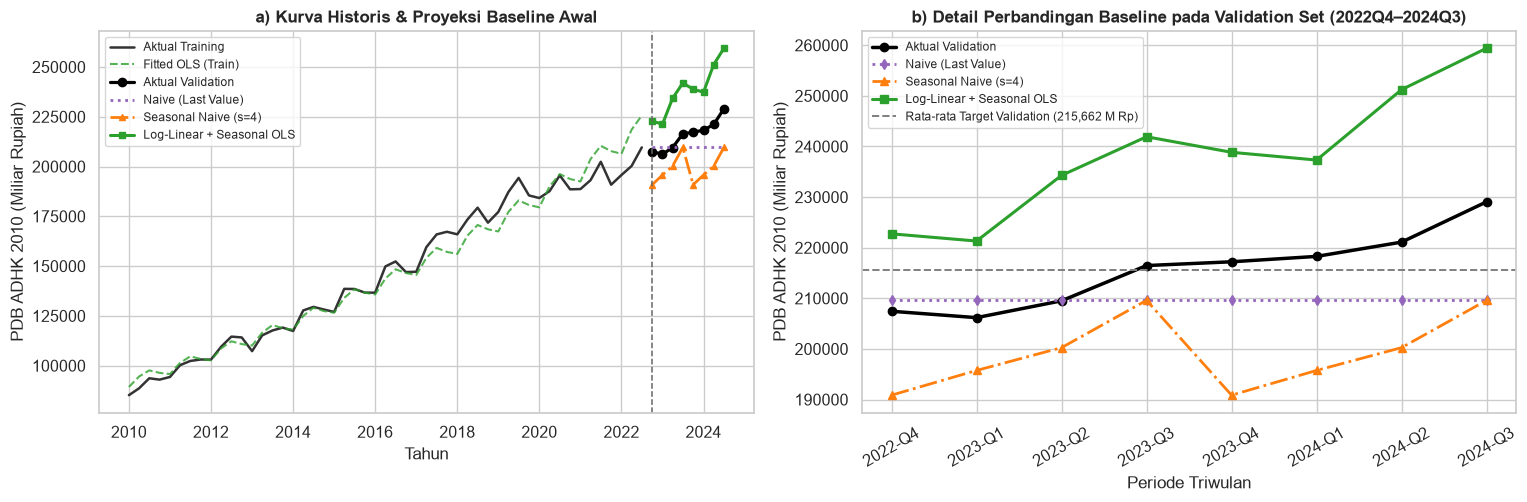

In [14]:
def evaluate_forecast(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    smape = float(np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100)
    return {
        'RMSE (Miliar Rp)': round(rmse, 2),
        'MAE (Miliar Rp)': round(mae, 2),
        'MAPE (%)': round(mape, 3),
        'sMAPE (%)': round(smape, 3),
    }

y_val = val_df['pdb_mamin_adhk_miliar_rp'].values
horizon_val = len(y_val)

# 1. Baseline 1 — Naive (Last Observed Value pada akhir Training Set)
pred_val_naive = np.repeat(y_train[-1], horizon_val)

# 2. Baseline 2 — Seasonal Naive (mengulang siklus 4 kuartal terakhir Training Set)
last_season_4 = y_train[-4:]
pred_val_snaive = np.tile(last_season_4, int(np.ceil(horizon_val / 4)))[:horizon_val]

# 3. Baseline 3 — Log-Linear Trend + Seasonal Dummy OLS (di-fit murni pada Training Set)
def make_trend_seasonal_matrix(sub_df: pd.DataFrame, start_t: int) -> np.ndarray:
    t_idx = np.arange(start_t, start_t + len(sub_df), dtype=float)
    q2 = (sub_df['triwulan'].values == 2).astype(float)
    q3 = (sub_df['triwulan'].values == 3).astype(float)
    q4 = (sub_df['triwulan'].values == 4).astype(float)
    return np.column_stack([t_idx, q2, q3, q4])

X_tr_base = make_trend_seasonal_matrix(train_df, start_t=0)
X_val_base = make_trend_seasonal_matrix(val_df, start_t=len(train_df))

ols_baseline = LinearRegression().fit(X_tr_base, np.log(y_train))
pred_train_ols = np.exp(ols_baseline.predict(X_tr_base))
pred_val_ols = np.exp(ols_baseline.predict(X_val_base))

baseline_table = pd.DataFrame([
    {'Model Baseline Awal': 'Baseline 1 — Naive (Last Value)', **evaluate_forecast(y_val, pred_val_naive)},
    {'Model Baseline Awal': 'Baseline 2 — Seasonal Naive (s = 4)', **evaluate_forecast(y_val, pred_val_snaive)},
    {'Model Baseline Awal': 'Baseline 3 — Log-Linear Trend + Seasonal Dummy (OLS)', **evaluate_forecast(y_val, pred_val_ols)},
]).sort_values('MAPE (%)').reset_index(drop=True)

print('=== Evaluasi Akurasi Baseline Awal pada Validation Set (2022-Q4 s.d. 2024-Q3) ===')
display(baseline_table)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

# Panel (a): Keseluruhan Training & Validation vs Proyeksi Baseline
axes[0].plot(train_df['tanggal'], y_train, color='#333333', lw=1.8, label='Aktual Training')
axes[0].plot(train_df['tanggal'], pred_train_ols, color='#2ca02c', ls='--', lw=1.5, alpha=0.8, label='Fitted OLS (Train)')
axes[0].plot(val_df['tanggal'], y_val, color='#000000', marker='o', lw=2.3, label='Aktual Validation')
axes[0].plot(val_df['tanggal'], pred_val_naive, color='#9467bd', ls=':', lw=2.0, label='Naive (Last Value)')
axes[0].plot(val_df['tanggal'], pred_val_snaive, color='#ff7f0e', ls='-.', lw=2.0, marker='^', ms=4.5, label='Seasonal Naive (s=4)')
axes[0].plot(val_df['tanggal'], pred_val_ols, color='#2ca02c', lw=2.2, marker='s', ms=4.5, label='Log-Linear + Seasonal OLS')
axes[0].axvline(val_df['tanggal'].iloc[0], color='#666666', ls='--', lw=1.1)
axes[0].set_title('a) Kurva Historis & Proyeksi Baseline Awal', fontweight='bold')
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('PDB ADHK 2010 (Miliar Rupiah)')
axes[0].legend(loc='upper left', fontsize=8.6)

# Panel (b): Zoom Validation Set + Garis Rata-Rata Aktual Validation
val_mean = float(np.mean(y_val))
axes[1].plot(val_df['periode'], y_val, color='#000000', marker='o', ms=6, lw=2.5, label='Aktual Validation')
axes[1].plot(val_df['periode'], pred_val_naive, color='#9467bd', ls=':', marker='d', ms=5, lw=2.0, label='Naive (Last Value)')
axes[1].plot(val_df['periode'], pred_val_snaive, color='#ff7f0e', ls='-.', marker='^', ms=5.5, lw=2.0, label='Seasonal Naive (s=4)')
axes[1].plot(val_df['periode'], pred_val_ols, color='#2ca02c', marker='s', ms=5.5, lw=2.2, label='Log-Linear + Seasonal OLS')
axes[1].axhline(val_mean, color='#7f7f7f', ls='--', lw=1.4, label=f'Rata-rata Target Validation ({val_mean:,.0f} M Rp)')
axes[1].set_title('b) Detail Perbandingan Baseline pada Validation Set (2022Q4–2024Q3)', fontweight='bold')
axes[1].set_xlabel('Periode Triwulan')
axes[1].set_ylabel('PDB ADHK 2010 (Miliar Rupiah)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.show()